# 01 · Data

Download the universe, check data quality and get a first look at prices, correlations and funding.

We trade **perpetual futures** (Binance USDⓈ-M), because shorting one leg of a pair is only practical with perps.
That gives us two data sets per coin: hourly prices and the funding rate history (paid every 8h).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make the repo root importable, whether Jupyter starts in notebooks/ or the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import data, strategy, backtest, plots

cfg = data.load_config()

## 1. Load config

`config.yaml` stores the universe as base coins; `data.perp_symbol` maps them to the ccxt perpetual symbol.
Dates are whole days and inclusive: train = [start, train_end], test = (train_end, end].

In [2]:
setup = cfg["setup"]
print(f"Exchange:  {setup['exchange']}")
print(f"Universe:  {[data.perp_symbol(c) for c in setup['universe']]}")
print(f"Timeframe: {setup['timeframe']}")
print(f"Period:    {setup['start']} to {setup['end']}  (train until {setup['train_end']})")

Exchange:  binanceusdm
Universe:  ['BTC/USDT:USDT', 'ETH/USDT:USDT', 'SOL/USDT:USDT', 'BNB/USDT:USDT', 'XRP/USDT:USDT', 'ADA/USDT:USDT', 'AVAX/USDT:USDT', 'LINK/USDT:USDT', 'DOT/USDT:USDT', 'LTC/USDT:USDT', 'DOGE/USDT:USDT', 'TRX/USDT:USDT']
Timeframe: 1h
Period:    2023-01-01 to 2026-10-31  (train until 2025-12-31)


## 2. Download / load data

`data.load_prices` reads the cached parquet files (run `python src/data.py` first if data/ is empty),
puts every coin on one complete hourly UTC grid, forward-fills gaps of up to `max_ffill_bars` bars
and drops coins with more than `max_missing_pct` missing bars. `data.load_funding` puts the funding
rates on the same grid (rate at each funding hour, 0 otherwise).

In [3]:
data.download_universe(cfg)  # no-op if all files are cached

prices = data.load_prices(cfg, verbose=False)
funding = data.load_funding(cfg, coins=list(prices.columns))
train_prices, test_prices = data.split_train_test(prices, setup["train_end"])

print(f"Prices: {prices.shape[0]} hourly bars x {prices.shape[1]} coins")
print(f"Train:  {train_prices.index[0]} to {train_prices.index[-1]} ({len(train_prices)} bars)")
print(f"Test:   {test_prices.index[0]} to {test_prices.index[-1]} ({len(test_prices)} bars)")
prices.tail(3)

[ 1/12] BTC   prices:  cached, skipped
[ 1/12] BTC   funding: cached, skipped
[ 2/12] ETH   prices:  cached, skipped
[ 2/12] ETH   funding: cached, skipped
[ 3/12] SOL   prices:  cached, skipped
[ 3/12] SOL   funding: cached, skipped
[ 4/12] BNB   prices:  cached, skipped
[ 4/12] BNB   funding: cached, skipped
[ 5/12] XRP   prices:  cached, skipped
[ 5/12] XRP   funding: cached, skipped
[ 6/12] ADA   prices:  cached, skipped
[ 6/12] ADA   funding: cached, skipped
[ 7/12] AVAX  prices:  cached, skipped
[ 7/12] AVAX  funding: cached, skipped
[ 8/12] LINK  prices:  cached, skipped
[ 8/12] LINK  funding: cached, skipped
[ 9/12] DOT   prices:  cached, skipped
[ 9/12] DOT   funding: cached, skipped
[10/12] LTC   prices:  cached, skipped
[10/12] LTC   funding: cached, skipped
[11/12] DOGE  prices:  cached, skipped
[11/12] DOGE  funding: cached, skipped
[12/12] TRX   prices:  cached, skipped
[12/12] TRX   funding: cached, skipped


Prices: 33600 hourly bars x 12 coins
Train:  2023-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00 (26304 bars)
Test:   2026-01-01 00:00:00+00:00 to 2026-10-31 23:00:00+00:00 (7296 bars)


,BTC,ETH,SOL,BNB,XRP,ADA,AVAX,LINK,DOT,LTC,DOGE,TRX
timestamp,,,,,,,,,,,,
2026-10-31 21:00:00+00:00,77633.1,2254.52,95.88,703.32,1.2526,0.1935,8.577,11.851,0.9467,56.03,0.07588,0.30369
2026-10-31 22:00:00+00:00,77498.8,2253.36,95.43,703.53,1.2513,0.1931,8.563,11.761,0.9474,55.78,0.07566,0.30169
2026-10-31 23:00:00+00:00,77522.6,2254.54,95.44,704.17,1.2514,0.1928,8.565,11.653,0.9456,55.73,0.07559,0.30347


## 3. Data quality

Raw data before cleaning: available bars, missing bars on the full hourly grid, the longest gap,
and the first/last timestamp per coin. We also look at the largest 1h move per coin as an outlier check
(a huge spike that immediately reverts would point to a bad tick).

In [4]:
quality = data.data_quality(data.load_raw_closes(cfg))

log_ret = np.log(prices).diff()
quality["max_abs_1h_return"] = log_ret.abs().max()
quality["time_of_max_move"] = log_ret.abs().idxmax()

quality.style.format({"missing_pct": "{:.2%}", "max_abs_1h_return": "{:.1%}"})

,bars,missing_bars,missing_pct,longest_gap,first,last,max_abs_1h_return,time_of_max_move
BTC,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,6.5%,2023-04-26 19:00:00+00:00
ETH,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,12.3%,2025-02-03 01:00:00+00:00
SOL,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,12.2%,2023-07-14 00:00:00+00:00
BNB,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,9.2%,2025-02-03 01:00:00+00:00
XRP,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,22.3%,2023-07-13 15:00:00+00:00
ADA,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,29.0%,2025-03-02 15:00:00+00:00
AVAX,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,16.3%,2023-06-10 04:00:00+00:00
LINK,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,13.8%,2025-10-10 21:00:00+00:00
DOT,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,24.7%,2025-10-10 21:00:00+00:00
LTC,33600,0,0.00%,0,2023-01-01 00:00:00+00:00,2026-10-31 23:00:00+00:00,20.3%,2025-10-10 21:00:00+00:00


## 4. Price overview

All coins rebased to 100 at the start, on a log scale so that equal percentage moves look equal.
The dashed line marks the end of the train period.

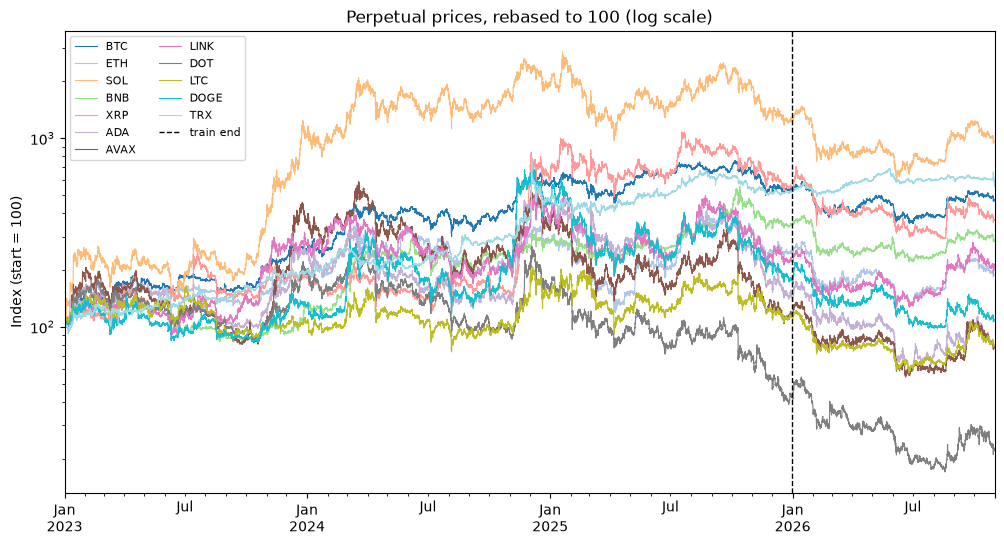

In [5]:
rebased = 100 * prices / prices.iloc[0]

fig, ax = plt.subplots(figsize=(12, 6))
rebased.plot(ax=ax, logy=True, lw=0.8, colormap="tab20")
ax.axvline(pd.Timestamp(setup["train_end"], tz="UTC"), color="k", ls="--", lw=1, label="train end")
ax.set_title("Perpetual prices, rebased to 100 (log scale)")
ax.set_xlabel("")
ax.set_ylabel("Index (start = 100)")
ax.legend(ncol=2, fontsize=8, loc="upper left")
plt.show()

## 5. Correlations

Correlation of hourly **log returns** on the **train period only** (the test period stays untouched).
We use returns, not price levels: two trending price series look highly correlated even when unrelated
(spurious correlation).

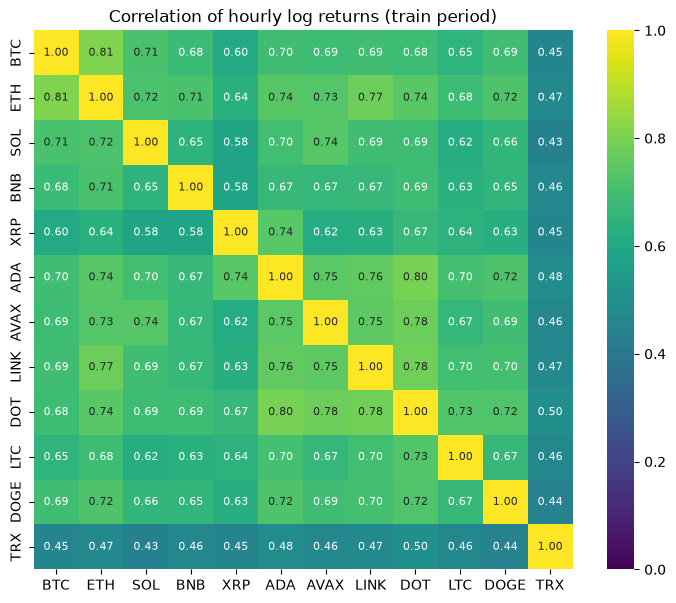

,,correlation
BTC,ETH,0.807857
ADA,DOT,0.795945
LINK,DOT,0.782605
AVAX,DOT,0.775322
ETH,LINK,0.774439
ADA,LINK,0.755090
AVAX,LINK,0.752653
ADA,AVAX,0.746093
ETH,DOT,0.741211
XRP,ADA,0.739442


In [6]:
train_ret = np.log(train_prices).diff().dropna()
corr = train_ret.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, square=True, ax=ax,
            annot_kws={"size": 8})
ax.set_title("Correlation of hourly log returns (train period)")
plt.show()

# Top pairs by correlation, upper triangle only so every pair appears once
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
top_pairs = corr.where(mask).stack().sort_values(ascending=False)
top_pairs.head(10).rename("correlation").to_frame()

## 6. Funding rates

Holders of a perpetual pay or receive funding every 8h: a **positive** rate means longs pay shorts.
In a pair trade we are long one leg and short the other, so funding is a cost on one leg and income
on the other. Annualized funding = average funding per hour × 24 × 365.

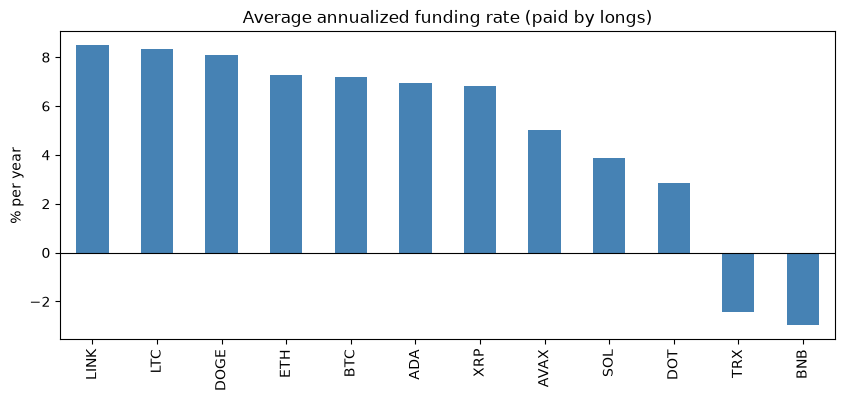

,full period,train,test
LINK,8.49%,9.56%,4.64%
LTC,8.32%,9.74%,3.19%
DOGE,8.09%,9.45%,3.17%
ETH,7.28%,8.72%,2.07%
BTC,7.18%,8.31%,3.12%
ADA,6.94%,8.42%,1.60%
XRP,6.81%,8.64%,0.21%
AVAX,5.01%,6.03%,1.30%
SOL,3.86%,5.10%,-0.60%
DOT,2.85%,4.74%,-3.99%


In [7]:
train_funding, test_funding = data.split_train_test(funding, setup["train_end"])
hours_per_year = 24 * 365
annual_funding = pd.DataFrame({
    "full period": funding.mean() * hours_per_year,
    "train": train_funding.mean() * hours_per_year,
    "test": test_funding.mean() * hours_per_year,
}).sort_values("full period", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
annual_funding["full period"].mul(100).plot.bar(ax=ax, color="steelblue")
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Average annualized funding rate (paid by longs)")
ax.set_ylabel("% per year")
plt.show()

annual_funding.style.format("{:.2%}")

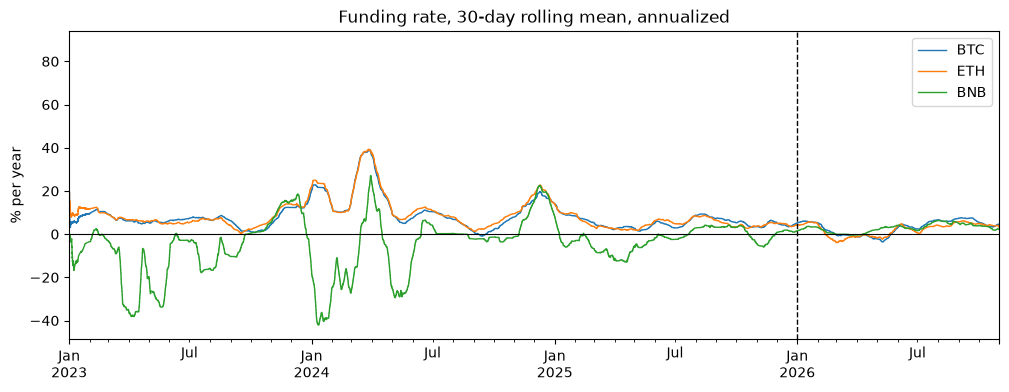

In [8]:
# Funding over time for three coins: rolling 30-day mean, annualized, to see regimes rather than noise
coins_to_plot = ["BTC", "ETH", "BNB"]
rolling_annual = funding[coins_to_plot].rolling("30D").mean() * hours_per_year * 100

fig, ax = plt.subplots(figsize=(12, 4))
rolling_annual.plot(ax=ax, lw=1)
ax.axhline(0, color="k", lw=0.8)
ax.axvline(pd.Timestamp(setup["train_end"], tz="UTC"), color="k", ls="--", lw=1)
ax.set_title("Funding rate, 30-day rolling mean, annualized")
ax.set_ylabel("% per year")
ax.set_xlabel("")
plt.show()

## 7. Observations

- **Data quality is clean.** All 12 perpetuals have the full 33,600 hourly bars from 2023-01-01 to 2026-10-31 with no missing bars, so no forward-filling was needed and no coin is dropped. Funding comes every 8h for every coin (4,200 events each).
- **Large moves are real, not bad ticks.** The biggest 1h moves cluster on known market-wide events (e.g. the crash of 10 Oct 2025 for LINK, DOT and LTC, 3 Feb 2025 for ETH and BNB), so we keep them. They are exactly the moments when a pair's spread can blow out, which is what the z-stop is for.
- **Prices diverge strongly in levels.** SOL rose ~12x over the train period while DOT lost more than half its value. Level correlation alone says little, so pair selection must rely on return correlation plus a cointegration test.
- **Return correlations are high across the board** (median 0.68 across all 66 pairs on train data, half of them between 0.63 and 0.72), driven by a common crypto market factor. The most correlated pairs are BTC–ETH (0.81) and a large-cap altcoin cluster (ADA, DOT, LINK, AVAX, ETH). These are natural candidates for notebook 02. TRX is the least correlated coin (about 0.45 with everything else).
- **Funding is material and regime-dependent.** Longs paid about 5–10% per year on most coins in the train period, with peaks near 40% per year in early 2024. BNB and TRX are the exceptions with near-zero or negative funding. In the test period funding is much lower (mostly 0–5%). For a market-neutral pair, the two legs' funding partly cancels, but a pair with very different funding (e.g. long BNB / short ETH) earns or pays the funding spread every 8h, so the backtest must include it.